# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [1]:
NAMES = "Anh Phan, Braden Cruz, Emerson Brown"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

1. The cost function for binary classification is binary cross entropy, multi-class classification is categorical cross entropy (or softmax loss), and regression is mean squared error. 
2. For binary classification, it has 1 unit with a sigmoid activation, which outputs the probability of the positive class. For multi-class classification, it has 1 unit per class with a softmax activation, so the outputs form a probability distribution that sums to 1. For regression, the output layer has 1 unit with no activation function, so predictions can be any real number. 
3. It is important to standardize the data so that all features are on a similar scale. If we do not standardize, features with large values dominate the weight updates, and the loss becomes elongated, which makes the gradient descent slow and unstable. Standardzing will help the model converge faster and treat all features fairly. 
4. You can detect overfitting by monitoring training and validation performance during training. If the training accuracy keeps improving (or training loss keeps dropping) while the validation accuracy stalls or the validation loss starts increasing, the model is memorizing the training data instead of learning patterns that generalize to new data. A large gap between very high training performance and much poorer test performance is also a sign of overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [13]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [14]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [15]:
# IMPLEMENTATION
class BinaryMLP(object):

    def __init__(self,
                 input_dim,
                 hidden_dim,
                 n_layers=1,
                 activation="relu",
                 learning_rate=0.01):

        self.n_layers = n_layers
        self.act = torch.relu if activation == "relu" else torch.tanh
        self.learning_rate = learning_rate

        # Hidden layer 1
        self.W_1 = torch.randn(input_dim, hidden_dim, requires_grad=True)
        self.b_1 = torch.randn(hidden_dim, requires_grad=True)
        self.params = [self.W_1, self.b_1]

        # Hidden layer 2
        if n_layers == 2:
            self.W_h2 = torch.randn(hidden_dim, hidden_dim, requires_grad=True)
            self.b_h2 = torch.randn(hidden_dim, requires_grad=True)
            self.params += [self.W_h2, self.b_h2]

        # Output layer
        self.W_2 = torch.randn(hidden_dim, 1, requires_grad=True)
        self.b_2 = torch.randn(1, requires_grad=True)
        self.params += [self.W_2, self.b_2]

    def forward(self, X):
        # 1- input -> hidden layer 1
        h = self.act(torch.matmul(X, self.W_1) + self.b_1)
        # 2- hidden layer 1 -> hidden layer 2 (if there is one)
        if self.n_layers == 2:
            h = self.act(torch.matmul(h, self.W_h2) + self.b_h2)
        # 3- hidden -> output layer, sigmoid gives P(y = 1)
        out = torch.matmul(h, self.W_2) + self.b_2
        return torch.sigmoid(out)

    def cost(self, probs, y):
        # Binary cross-entropy
        eps = 1e-12
        return -(y * torch.log(probs + eps) + (1 - y) * torch.log(1 - probs + eps)).mean()

    def fit(self, X, y, n_epochs=100):
        # y to float tensor (0s & 1s) with shape (n, 1)
        for epoch in range(n_epochs):

            randperm = torch.randperm(X.shape[0])
            for ii in randperm:
                x_batch, y_batch = X[ii], y[ii]
                # Forward pass
                probs = self.forward(x_batch)
                # Cost
                cost = self.cost(probs, y_batch)
                # Backward pass
                cost.backward()
                # Gradient descent + zero gradients
                with torch.no_grad():
                    for p in self.params:
                        p -= self.learning_rate * p.grad
                        p.grad.zero_()

            # Print full training cost every 10 epochs
            if epoch % 10 == 0:
                with torch.no_grad():
                    full_cost = self.cost(self.forward(X), y)
                print(f"Epoch {epoch}, Cost: {full_cost.item():.4f}")
        return self

    def predict(self, X):
        with torch.no_grad():
            probs = self.forward(X)
            predicted = (probs >= 0.5).long().squeeze(-1)   # class 1 if P(y=1) >= 0.5
        return predicted

In [16]:
# DATA PREPARATION

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features (fit on training data only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

# Labels as a (n, 1) float column for the BCE cost
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

In [17]:
# TRAINING AND EVALUATION
import io, contextlib
from sklearn.metrics import accuracy_score

hidden_units_list = [2, 4, 8, 16, 32, 64]
layers_list = [1, 2]
activations = ["relu", "tanh"]

results = []

for activation in activations:
    for n_layers in layers_list:
        for hidden_dim in hidden_units_list:
            torch.manual_seed(42)

            model = BinaryMLP(input_dim=X_train.shape[1], hidden_dim=hidden_dim,
                              n_layers=n_layers, activation=activation,
                              learning_rate=0.01)

            with contextlib.redirect_stdout(io.StringIO()):
                model.fit(X_train, y_train_t, n_epochs=100)

            train_acc = accuracy_score(y_train, model.predict(X_train).numpy())
            test_acc = accuracy_score(y_test, model.predict(X_test).numpy())

            results.append({"activation": activation,
                            "hidden layers": n_layers,
                            "hidden units": hidden_dim,
                            "train accuracy": round(train_acc, 3),
                            "holdout accuracy": round(test_acc, 3),
                            "gap": round(train_acc - test_acc, 3)})

            print(f"{activation:4s} | layers={n_layers} | units={hidden_dim:3d} | "
                  f"train={train_acc:.3f} | holdout={test_acc:.3f}")

results_df = pd.DataFrame(results)
results_df

relu | layers=1 | units=  2 | train=0.869 | holdout=0.850
relu | layers=1 | units=  4 | train=0.880 | holdout=0.890
relu | layers=1 | units=  8 | train=0.969 | holdout=0.970
relu | layers=1 | units= 16 | train=0.976 | holdout=0.990
relu | layers=1 | units= 32 | train=0.978 | holdout=0.985
relu | layers=1 | units= 64 | train=0.975 | holdout=0.985
relu | layers=2 | units=  2 | train=0.863 | holdout=0.845
relu | layers=2 | units=  4 | train=0.970 | holdout=0.990
relu | layers=2 | units=  8 | train=0.978 | holdout=0.985
relu | layers=2 | units= 16 | train=0.971 | holdout=0.975
relu | layers=2 | units= 32 | train=0.979 | holdout=0.985
relu | layers=2 | units= 64 | train=0.966 | holdout=0.970
tanh | layers=1 | units=  2 | train=0.868 | holdout=0.845
tanh | layers=1 | units=  4 | train=0.971 | holdout=0.965
tanh | layers=1 | units=  8 | train=0.973 | holdout=0.990
tanh | layers=1 | units= 16 | train=0.976 | holdout=0.990
tanh | layers=1 | units= 32 | train=0.975 | holdout=0.995
tanh | layers=

,activation,hidden layers,hidden units,train accuracy,holdout accuracy,gap
0,relu,1,2,0.869,0.850,0.019
1,relu,1,4,0.880,0.890,-0.010
2,relu,1,8,0.969,0.970,-0.001
3,relu,1,16,0.976,0.990,-0.014
4,relu,1,32,0.978,0.985,-0.007
5,relu,1,64,0.975,0.985,-0.010
6,relu,2,2,0.863,0.845,0.018
7,relu,2,4,0.970,0.990,-0.020
8,relu,2,8,0.978,0.985,-0.007
9,relu,2,16,0.971,0.975,-0.004


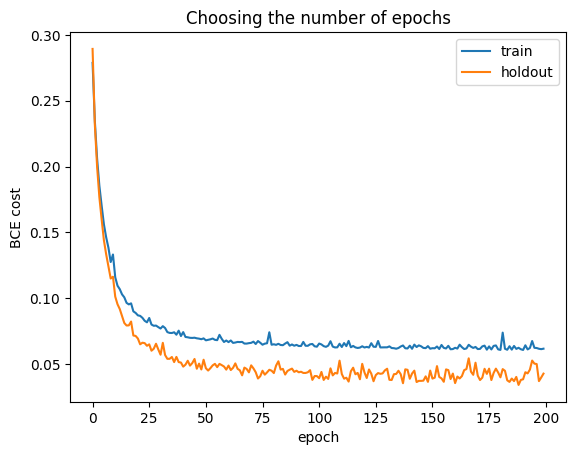

In [18]:
import io, contextlib
import matplotlib.pyplot as plt

torch.manual_seed(42)
model = BinaryMLP(input_dim=X_train.shape[1], hidden_dim=16, n_layers=1,
                  activation="relu", learning_rate=0.01)

train_hist, test_hist = [], []
for epoch in range(200):
    with contextlib.redirect_stdout(io.StringIO()):
        model.fit(X_train, y_train_t, n_epochs=1)   # one more epoch each loop
    with torch.no_grad():
        train_hist.append(model.cost(model.forward(X_train), y_train_t).item())
        test_hist.append(model.cost(model.forward(X_test), y_test_t).item())

plt.plot(train_hist, label="train")
plt.plot(test_hist, label="holdout")
plt.xlabel("epoch"); plt.ylabel("BCE cost"); plt.legend()
plt.title("Choosing the number of epochs")
plt.show()

**Reflection:**

I chose to use 100 as my number of epochs because there is a huge drop for both the holdout and training data until about 25 epochs. Once they hit about 50 epochs, they start to level out at each cost, at roughly 0.04 and 0.06. Despite the slightly varying costs, we can assume the model does well since both share roughly the same shaped curves. This continues until the 200 epoch mark, where we see no real improvement with the increased value. For this reason, I chose to use 100, since it shows a fairly stable cost without using more epochs than necessary to get roughly the same value.  
  
In regards to the number of hidden units, we see that the accuracy rises with more. When only having 2, we have a fairly underfit model, but as we gain more, we also gain the capacity to make the decision boundary better. We also know we don't really have an overfit model since the gap remains small between train and holdout. We see that there is a bit of a plateau following the 16 units, so the 8-16 units for a dataset like this is fairly good.  
  
When it comes to the 1 vs 2 layers, we can see that the second layer is helpful when there is a small network. Like in the ReLU with 4 units, the accuracy jumps because having 2 layers allows the second to build on the first. With too little units, building on one another doesn't help since there is not much information passed on. With too many units, the second layer doesn't add much or makes it worse. So, 1 layer for this type of data is enough.  
  
Both proved to be accurate. While Tanh worked better with the smaller number of units, ReLU requires more. This is due to the structure. If Tanh is known for producing a smoother shape, it can fit the curved boundary easily with few than ReLU. So, both have their benefits and work well in different situations.

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [7]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [8]:
# IMPLEMENTATION 
class MultiClassMLP(object):

    def __init__(self,
                 input_dim,
                 hidden_dim,
                 n_classes,
                 n_layers=1,
                 activation="relu",
                 learning_rate=0.01):

        self.n_layers = n_layers
        self.act = torch.relu if activation == "relu" else torch.tanh
        self.learning_rate = learning_rate

        # Hidden layer 1
        self.W_1 = torch.randn(input_dim, hidden_dim, requires_grad=True)
        self.b_1 = torch.randn(hidden_dim, requires_grad=True)
        self.params = [self.W_1, self.b_1]

        # Hidden layer 2 (just extra set of weights + intercept)
        if n_layers == 2:
            self.W_h2 = torch.randn(hidden_dim, hidden_dim, requires_grad=True)
            self.b_h2 = torch.randn(hidden_dim, requires_grad=True)
            self.params += [self.W_h2, self.b_h2]

        # Output layer (one unit per class)
        self.W_2 = torch.randn(hidden_dim, n_classes, requires_grad=True)
        self.b_2 = torch.randn(n_classes, requires_grad=True)
        self.params += [self.W_2, self.b_2]

    def forward(self, X):
        # 1- input -> hidden layer 1
        h = self.act(torch.matmul(X, self.W_1) + self.b_1)
        # 2- hidden layer 1 -> hidden layer 2 (if there is one)
        if self.n_layers == 2:
            h = self.act(torch.matmul(h, self.W_h2) + self.b_h2)
        # 3- hidden -> output layer, softmax gives class probabilities
        out = torch.matmul(h, self.W_2) + self.b_2
        return F.softmax(out, dim=-1)   # dim=-1 works for a single sample or a batch

    def cost(self, probs, y):
        # Categorical cross-entropy
        eps = 1e-12
        return -(y * torch.log(probs + eps)).sum(dim=-1).mean()

    def fit(self, X, y, n_epochs=100):
        # y must be one-hot encoded (float tensor)
        for epoch in range(n_epochs):

            randperm = torch.randperm(X.shape[0])
            for ii in randperm:
                x_batch, y_batch = X[ii], y[ii]

                # Forward pass
                probs = self.forward(x_batch)

                # Cost
                cost = self.cost(probs, y_batch)

                # Backward pass
                cost.backward()

                # Gradient descent step (manual) + zero gradients
                with torch.no_grad():
                    for p in self.params:
                        p -= self.learning_rate * p.grad
                        p.grad.zero_()

            # Print full training cost every 10 epochs
            if epoch % 10 == 0:
                with torch.no_grad():
                    full_cost = self.cost(self.forward(X), y)
                print(f"Epoch {epoch}, Cost: {full_cost.item():.4f}")
        return self

    def predict(self, X):
        with torch.no_grad():
            probs = self.forward(X)
            predicted = torch.argmax(probs, dim=-1)   # class with highest probability
        return predicted

In [9]:
# DATA PREPARATION 
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# One-hot encode labels (needs for softmax + categorical cross-entropy)
encoder = OneHotEncoder(sparse_output=False)
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1))
y_test_oh = encoder.transform(y_test.reshape(-1, 1))

# Convert to torch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train_oh = torch.tensor(y_train_oh, dtype=torch.float32)
y_test_oh = torch.tensor(y_test_oh, dtype=torch.float32)

# We want y_train and y_test as integer labels for evaluation (accuracy)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

In [10]:
# TRAINING AND EVALUATION 
import io, contextlib
from sklearn.metrics import accuracy_score

hidden_units_list = [2, 4, 8, 16, 32, 64]
layers_list = [1, 2]
activations = ["relu", "tanh"]

results = []

for activation in activations:
    for n_layers in layers_list:
        for hidden_dim in hidden_units_list:
            torch.manual_seed(42)

            model = MultiClassMLP(input_dim=X_train.shape[1], hidden_dim=hidden_dim,
                                  n_classes=3, n_layers=n_layers,
                                  activation=activation, learning_rate=0.01)

            with contextlib.redirect_stdout(io.StringIO()):
                model.fit(X_train, y_train_oh, n_epochs=100)

            train_acc = accuracy_score(y_train.numpy(), model.predict(X_train).numpy())
            test_acc = accuracy_score(y_test.numpy(), model.predict(X_test).numpy())

            results.append({"activation": activation,
                            "hidden layers": n_layers,
                            "hidden units": hidden_dim,
                            "train accuracy": round(train_acc, 3),
                            "holdout accuracy": round(test_acc, 3),
                            "gap": round(train_acc - test_acc, 3)})

            print(f"{activation:4s} | layers={n_layers} | units={hidden_dim:3d} | "
                  f"train={train_acc:.3f} | holdout={test_acc:.3f}")

results_df = pd.DataFrame(results)
results_df

relu | layers=1 | units=  2 | train=0.715 | holdout=0.695
relu | layers=1 | units=  4 | train=0.812 | holdout=0.785
relu | layers=1 | units=  8 | train=0.821 | holdout=0.795
relu | layers=1 | units= 16 | train=0.814 | holdout=0.795
relu | layers=1 | units= 32 | train=0.815 | holdout=0.785
relu | layers=1 | units= 64 | train=0.810 | holdout=0.790
relu | layers=2 | units=  2 | train=0.334 | holdout=0.330
relu | layers=2 | units=  4 | train=0.819 | holdout=0.795
relu | layers=2 | units=  8 | train=0.816 | holdout=0.800
relu | layers=2 | units= 16 | train=0.810 | holdout=0.810
relu | layers=2 | units= 32 | train=0.828 | holdout=0.805
relu | layers=2 | units= 64 | train=0.823 | holdout=0.800
tanh | layers=1 | units=  2 | train=0.811 | holdout=0.795
tanh | layers=1 | units=  4 | train=0.816 | holdout=0.790
tanh | layers=1 | units=  8 | train=0.820 | holdout=0.805
tanh | layers=1 | units= 16 | train=0.823 | holdout=0.795
tanh | layers=1 | units= 32 | train=0.810 | holdout=0.790
tanh | layers=

,activation,hidden layers,hidden units,train accuracy,holdout accuracy,gap
0,relu,1,2,0.715,0.695,0.020
1,relu,1,4,0.812,0.785,0.027
2,relu,1,8,0.821,0.795,0.026
3,relu,1,16,0.814,0.795,0.019
4,relu,1,32,0.815,0.785,0.030
5,relu,1,64,0.810,0.790,0.020
6,relu,2,2,0.334,0.330,0.004
7,relu,2,4,0.819,0.795,0.024
8,relu,2,8,0.816,0.800,0.016
9,relu,2,16,0.810,0.810,0.000


## Reflection and Discussion

1. A very small number of hidden units can cause underfitting. For example, with one ReLU layer and 2 units, the model only reached an accuracy of 0.715 for the training set, and 0.695 for the holdout. Two units aren't enough to separate three classes, and a likely dead ReLU unit leaves the model with even less capacity. Moving to 4 units gave better accuracy (0.812 train/0.785 holdout). However, beyond 4-8 units, the performance plateaus. From 8-64 units with one ReLU layer, the holdout accuracy stays between 0.785 and 0.795. The gap stayed small, so width alone did not cause meaningful overfitting with one layer. BUT, very wide layers can also hurt optimization. With one Tanh layer and 64 units, both train and holdout accuracy dropped (0.782 and 0.765). This is because wide layers produce large pre-activations that saturate Tanh, where gradients are near 0, and the model is unable to fully converge within 100 epochs. 
2. With 2 units per layer, the 2 layer ReLU model becomes fragile and is essentially based on chance (0.334 train / 0.330 holdout). Both second layer units died, so the output layer always predict the same class. With 4 or more units, the ReLU networks improve slightly. Holdout accuracy rose to 0.795-0.810 versus the 0.785-0.795 with one layer. With 32-64 units, 2 layer Tanh networks start overfitting. The training accuracy here reaches its highest values (0.845 and 0.853), but holdout accuracy stays around 0.80. Therefore, depth only brings a small holdout gain, and made training less reliable at small sizes and increased overfitting at large sizes. 
3. For small networks, Tanh is more robust. With 2 units, Tanh reached 0.795 holdout accuracy, compared with 0.695 (1 layer) and 0.330 (2 layers) for ReLU. Tanh's gradient is never exactly 0, while ReLU's is for negative input. So, in Tanh, every unit keeps getting a gradient, while ReLU units can die and stop learning. For larger networks, ReLU is more stable because it doesn't saturate for positive inputs, so wide ReLU layers keep learning well. The train and holdout gap with ReLU was below 0.03 in every configuration, while wide 2 layer Tanh networks showed the clearest overfitting. 

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [11]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [12]:
# USE AS MANY CELLS AS NEEDED

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

From what we have learned in class about classes, I think that we could have used a base parent class to hold all of the code that was shared between tasks. This would have made it more efficient, allowing us to simply call on the base class and then use less code to change the parts that were specific to each section. For example, the __init__, forward, and fit code all would have been very similar, with just small changes to output size and activation. Then, within each task, we could make the child classes that would define tha different parts. This could include the activation, cost, and prediction steps. This method would allow for a cleaner and concise file that is far easier to digest and understand, along with being easier to fix and add to. If there is a problem, fixing the parent class would subsequently fix the child classes as well. It would also create an easy way to add more child classes if you wanted to beyond Binary, Multi-Class, and Regression without redoing all of the code. 

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE